# 27 — Binary Educational Competition Optimizer (BECO) for feature selection

Continuous algorithm: *Lian J. et al. (2024). The educational competition optimizer. Int. J. Syst. Sci.*  
Binarised with the **Unified Binarization Framework (UBF)**: deterministic sign mapping, density-diverse initial population, fitness memoisation and elite bit-flip local search. RS = random-search control under the same framework. Protocol: see `00_data_and_protocol`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fsbench import experiment as ex, plots
pd.set_option("display.width", 200, "display.max_columns", 40)

In [2]:
METHOD = "ECO"
recs = ex.run_method(METHOD)
base = {m: ex.run_method(m) for m in ("ANOVA", "Chi2", "AllFeatures", "RS")}
df = ex.flatten(recs)
print(len(recs), "runs")

80 runs


## Performance on the test split (mean ± std over 10 runs)

In [3]:
plots.summary_table(df, by=("dataset", "classifier"))

,dataset,classifier,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,n_selected,search_time_s
0,dermatology,ANN,0.9736 ± 0.0117,0.9746 ± 0.0119,0.9695 ± 0.0131,0.9708 ± 0.0127,0.9978 ± 0.0016,18.2 ± 3.7059,5.705 ± 1.072
1,dermatology,DT,0.9509 ± 0.0178,0.9475 ± 0.0178,0.9379 ± 0.018,0.941 ± 0.0172,0.9641 ± 0.0106,18.2 ± 3.7059,5.705 ± 1.072
2,dermatology,KNN,0.9509 ± 0.0183,0.9491 ± 0.0181,0.9401 ± 0.0227,0.9423 ± 0.0212,0.9955 ± 0.0051,18.2 ± 3.7059,5.705 ± 1.072
3,dermatology,RF,0.9709 ± 0.0112,0.9713 ± 0.0118,0.9657 ± 0.0124,0.9672 ± 0.0121,0.9981 ± 0.0014,18.2 ± 3.7059,5.705 ± 1.072
4,dermatology,SVM,0.9673 ± 0.0107,0.9691 ± 0.0102,0.9615 ± 0.0119,0.9632 ± 0.0114,0.9978 ± 0.0016,18.2 ± 3.7059,5.705 ± 1.072
5,dermatology,XGB,0.9573 ± 0.0161,0.9549 ± 0.02,0.9506 ± 0.0175,0.9516 ± 0.0181,0.9958 ± 0.0013,18.2 ± 3.7059,5.705 ± 1.072
6,ionosphere,ANN,0.9019 ± 0.0214,0.9026 ± 0.0234,0.8823 ± 0.0249,0.8907 ± 0.0242,0.9463 ± 0.0248,8.6 ± 1.1738,4.5448 ± 0.835
7,ionosphere,DT,0.8925 ± 0.026,0.8873 ± 0.0274,0.8773 ± 0.0311,0.8815 ± 0.0291,0.8773 ± 0.0311,8.6 ± 1.1738,4.5448 ± 0.835
8,ionosphere,KNN,0.8745 ± 0.0252,0.8906 ± 0.0231,0.8378 ± 0.0337,0.8544 ± 0.0321,0.9309 ± 0.0202,8.6 ± 1.1738,4.5448 ± 0.835
9,ionosphere,RF,0.9057 ± 0.0183,0.9025 ± 0.0197,0.8911 ± 0.0222,0.896 ± 0.0206,0.9719 ± 0.0138,8.6 ± 1.1738,4.5448 ± 0.835


## Comparison with the classical filters (F1-macro, averaged over the six classifiers)

In [4]:
allb = pd.concat([df] + [ex.flatten(r) for r in base.values()])
pivot = allb.groupby(["dataset", "method"]).f1_macro.mean().unstack().round(4)
pivot

method,ANOVA,AllFeatures,Chi2,ECO,RS
dataset,,,,,
dermatology,0.9676,0.9568,0.9568,0.9560,0.9552
ionosphere,0.8734,0.8907,0.8734,0.8861,0.8765
musk1,0.8449,0.8634,0.8603,0.8534,0.8553
sonar,0.8293,0.8317,0.8188,0.7900,0.7940
spectf,0.5448,0.5448,0.5448,0.5535,0.5471
vehicle,0.6656,0.7311,0.6558,0.7204,0.7273
wdbc,0.9294,0.9442,0.9462,0.9417,0.9291
wine,0.9628,0.9524,0.9542,0.9503,0.9530


In [5]:
allb.groupby(["dataset", "method"])[["n_selected", "search_time_s"]].mean().unstack().round(2)

n_selected                                search_time_s                                
method           ANOVA AllFeatures   Chi2   ECO    RS         ANOVA AllFeatures  Chi2    ECO     RS
dataset                                                                                            
dermatology       24.0        34.0   34.0  18.2  18.1          0.36         0.0  0.23   5.71  13.37
ionosphere         3.0        33.0    3.0   8.6   6.4          0.33         0.0  0.32   4.54  15.02
musk1             66.0       166.0  133.0  51.8  55.9          0.38         0.0  0.28  12.92  21.06
sonar             24.0        60.0   30.0  24.5  21.5          0.30         0.0  0.28   5.70  11.13
spectf            44.0        44.0   44.0  20.8  16.9          0.31         0.0  0.20   5.05  12.17
vehicle            9.0        18.0    7.0   9.6  10.1          0.46         0.0  0.49   5.49  28.40
wdbc              18.0        30.0   21.0  11.8   9.9          0.37         0.0  0.35   5.49  20.84
wine               9.0        13.0    8.0   6.5   5.8          0.18         0.0  0.19   1.65   7.11

## Convergence: best-so-far fitness per iteration
A flat tail means the search converged within the budget; a still-decreasing tail means more iterations could help.

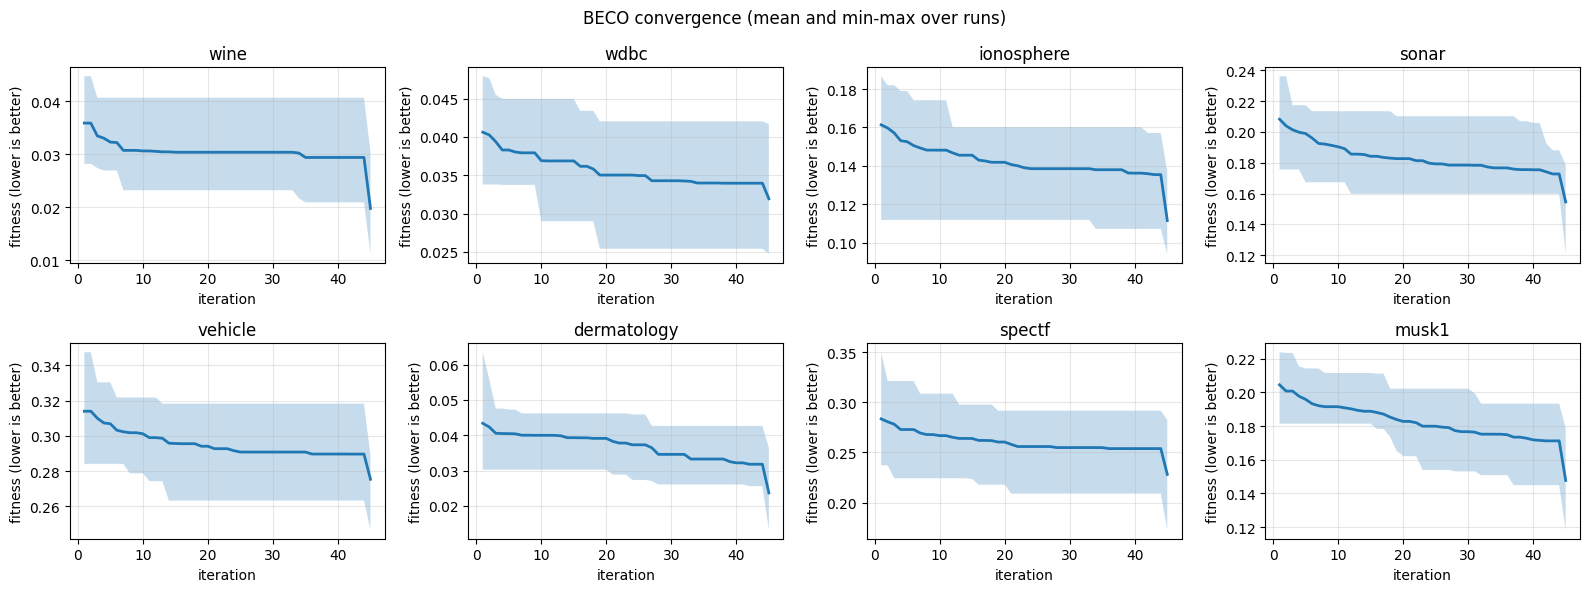

In [6]:
plots.convergence(recs, title="BECO convergence (mean and min-max over runs)", name="convergence_ECO");

## Confusion matrices and ROC curves (run 0, KNN)

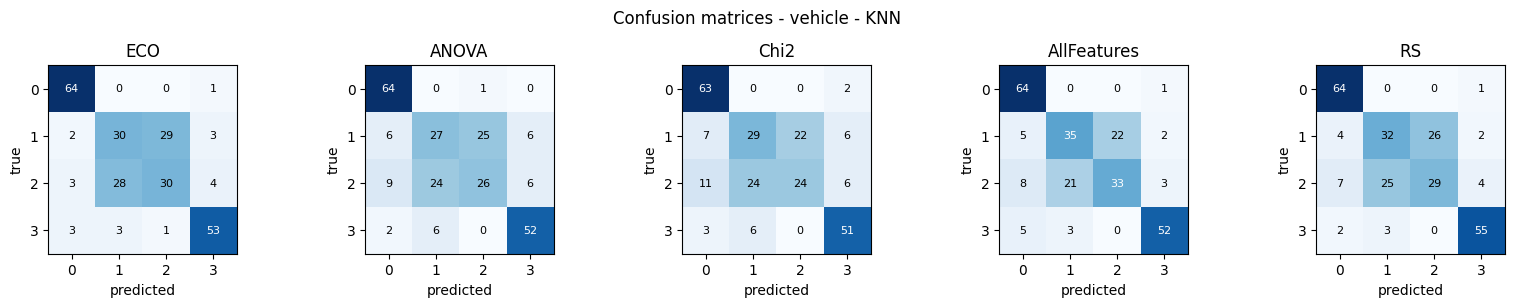

In [7]:
ds = "vehicle"
plots.confusion_matrices({METHOD: recs, **base}, ds, name=f"cm_{METHOD}_{ds}");

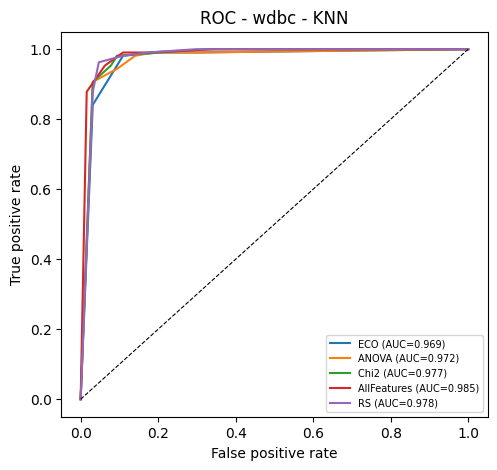

In [8]:
plots.roc_curves({METHOD: recs, **base}, "wdbc", name=f"roc_{METHOD}_wdbc");

## Computation
`n_classifier_fits` counts real classifier trainings; `cache_hits` are FEs served by the memo.

In [9]:
pd.DataFrame([{k: r[k] for k in ("dataset", "run", "n_selected", "time_s", "n_classifier_fits", "cache_hits")} for r in recs]).groupby("dataset").mean().round(2)

,run,n_selected,time_s,n_classifier_fits,cache_hits
dataset,,,,,
dermatology,4.5,18.2,5.71,285.7,714.3
ionosphere,4.5,8.6,4.54,246.7,753.3
musk1,4.5,51.8,12.92,507.4,492.6
sonar,4.5,24.5,5.70,352.5,647.5
spectf,4.5,20.8,5.05,293.0,707.0
vehicle,4.5,9.6,5.49,176.2,823.8
wdbc,4.5,11.8,5.49,234.2,765.8
wine,4.5,6.5,1.65,133.3,866.7
